In [2]:
# 数据处理与分析相关的库
import numpy as np
import pandas as pd
import xarray as xr
import statsmodels.api as sm
import pickle
from scipy.stats import pearsonr
from arch.bootstrap import MovingBlockBootstrap
from scipy.stats import norm

# 数据可视化相关的库
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D

# 系统路径和多进程相关的库
import os
import sys
from multiprocessing import Pool, cpu_count

# 引入自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

# 引导与警告设置
import warnings
warnings.simplefilter("ignore")  # Suppress all warnings

from matplotlib import rcParams
from matplotlib import font_manager


def is_leap_year(year): # 判断是否为闰年
    if year % 4 == 0:
        if year % 100 == 0:
            if year % 400 == 0:
                return True
            else:
                return False
        else:
            return True
    else:
        return False

def days_in_month(year, month): # 获取指定年份和月份的天数
    if month in [1, 3, 5, 7, 8, 10, 12]:
        return 31
    elif month in [4, 6, 9, 11]:
        return 30
    elif month == 2:
        if is_leap_year(year):
            return 29
        else:
            return 28
    else:
        return None

def day_of_year(year, month, day): # 获取指定日期在一年中的第几天
    total_days = 0
    for m in range(1, month):
        total_days += days_in_month(year, m)
    total_days += day
    return total_days
    
def time_to_decimal(time):
    if time.shape[0] == 2:
        time = np.vstack((time, np.ones((1, time.shape[1]))*15))
    years = np.squeeze(time[0, :]).astype(int)
    months = np.squeeze(time[1, :]).astype(int)
    days = np.squeeze(time[2, :]).astype(int)
    time_decimal = np.full(len(years), np.nan)
    for i, (year, month, day) in enumerate(zip(years, months, days)):
        day_of_year_value = day_of_year(year, month, day)
        if is_leap_year(year):
            time_decimal[i] = day_of_year_value / 366 + year
        else:
            time_decimal[i] = day_of_year_value / 365 + year
    return time_decimal

def smooth_cycle_cal(time, data, period, mins_trend=None):

    filt = ccg_filter.ccgFilter(time, data)
    start_time = np.floor(time[0]).astype(int)
    end_time = np.ceil(time[-1]).astype(int)
    all_dates = []
    for year in range(start_time, end_time + 1):
        yearly_dates = pd.date_range(start=f'{year}-01-01', end=f'{year}-12-31', periods=period)
        all_dates.extend(yearly_dates)
    year = [date.year for date in all_dates]
    month = [date.month for date in all_dates]
    day = [date.day for date in all_dates]
    date_array = np.vstack([year, month, day])
    time = time_to_decimal(date_array)

    trend = filt.getTrendValue(time)
    smooth =  filt.getSmoothValue(time)
    # harmonics = filt.getHarmonicValue(time)
    smooth_cycle = smooth
    if mins_trend is not None:
        smooth_cycle = smooth_cycle - trend

    return smooth_cycle, time

def cal_cum_amp(time, flux, period, st_time, ed_time):

    sc, time_sc = smooth_cycle_cal(time, flux, period=period)
    sc = np.nancumsum(sc)/period
    amp_temp = []
    for t in np.arange(st_time, ed_time-1):
        idx_t = np.where((time_sc >= t) & (time_sc < t+1))[0]
        amp_temp.append(np.nanmax(sc[idx_t]) - np.nanmin(sc[idx_t]))
    
    amp = np.array(amp_temp)
    return amp

def calculate_grid_area(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

In [3]:
## Inversion中只包含碳通量的AMP信息
model_dict = {}
folder_path = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/data/Land-flux-interp/Inversion/'
files = sorted([f for f in os.listdir(folder_path) if f.endswith('.nc')])
folder_out = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/data/Land-flux-AMP/regional/Inversion/'
lat_select = np.array([50, 90])

files = os.listdir(folder_path)
for file in files:
    file_path = os.path.join(folder_path, file)
    ds = xr.open_dataset(file_path)
    model = file_path.split('/')[-1].split('-')[0]
    data = ds.land.values # KgC/m2/s
    lon = ds.lon.values
    lat = ds.lat.values
    time = ds.time
    year = time.dt.year.values
    month = time.dt.month.values
    time_decimal = time_to_decimal(np.vstack((year, month)))
    area = calculate_grid_area(lat, lon) # m2
    data = data * area[np.newaxis, :, :] * (3600*24*365) * 1e-12 # PgC/yr

    # Boreal region mask
    lat_mask = (lat >= lat_select[0]) & (lat <= lat_select[1])
    data_boreal = np.nansum(data[:, lat_mask, :], axis=(1, 2))
    amp = []

    for period in [60, 120, 180]:
        st = np.floor(time_decimal[0])
        et = np.ceil(time_decimal[-1])
        temp = cal_cum_amp(time_decimal, data_boreal, period, st, et)
        amp.append(temp)

    amp = np.array(amp)
    time_amp = np.arange(st, et-1)

    model_dict[model] = {
        'amp': amp,
        'time': time_amp
    }

In [4]:
## Trendy中包含NBP的AMP信息

folder_path = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/data/Land-flux-interp/Trendy/'
files = sorted([f for f in os.listdir(folder_path) if f.endswith('.nc')])
folder_out = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/data/Land-flux-AMP/regional/Trendy/'
exp_list = ['S3']
var_list = ['nbp'] # KgC/m2/s
model_list = os.listdir(os.path.join(folder_path, exp_list[0]))
lat_select = np.array([50, 90])

data_trendy = []
for exp in exp_list:
    for model in model_list:
        file_path = os.path.join(folder_path, exp, model)
        file = os.listdir(file_path)[0]
        ds = xr.open_dataset(os.path.join(file_path, file))
        data = ds.nbp.values # KgC/m2/s
        lon = ds.lon.values
        lat = ds.lat.values
        time = ds.time
        year = time.dt.year.values
        month = time.dt.month.values
        time_decimal = time_to_decimal(np.vstack((year, month)))
        area = calculate_grid_area(lat, lon) # m2
        data = data * area[np.newaxis, :, :] * (3600*24*365) * 1e-12 # PgC/yr

        # Boreal region mask
        lat_mask = (lat >= lat_select[0]) & (lat <= lat_select[1])
        data_boreal = np.nansum(data[:, lat_mask, :], axis=(1, 2))
        amp = []

        for period in [60, 120, 180]:
            st = np.floor(time_decimal[0])
            et = np.ceil(time_decimal[-1])
            temp = cal_cum_amp(time_decimal, data_boreal, period, st, et)
            amp.append(temp)

        amp = np.array(amp)
        time_amp = np.arange(st, et-1)
        data_trendy.append(amp)

data_trendy = np.array(data_trendy).mean(axis=0)
model_dict['Trendy'] = {
    'amp': data_trendy,
    'time': time_amp
}


In [5]:
# ==========================================
# 收集所有文件（individual + ensemble）
# ==========================================
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/each/'

files_to_process = [(os.path.join(folder, f), f.split('.')[0]) for f in os.listdir(folder)]

# ==========================================
# 统一处理所有模型
# ==========================================
for file_path, model in files_to_process:
    with xr.open_dataset(file_path) as ds:
        amp_region = ds['amp_cum_region'].values
        time = ds['time'].values
        
        amp_region = amp_region[-1]  # 只取最后一个region
        model_dict[model]['amp_exp'] = amp_region
        print(model, amp_region, '\n')


Jena [2.84959673 2.71812901 2.61677179 2.65654742 2.7716006  2.58792914
 2.6918831  2.76793082 2.70134093 2.82634995 2.88746741 2.87571984
 2.94373064 2.82833074 2.77106577 2.6718231  2.85155721 2.73647844
 2.83105641 2.79084543 2.97742985 2.76934114 2.8206846  3.04205179
 3.26331035 2.94603316 3.01892113 2.92037042 3.08284825 2.94158696
 3.13141755 2.96979251 3.16973364 2.84052127 3.04467113 3.22026463
 2.9877142  2.98466279 3.23400937 2.92884502 3.03578328] 

Trendy [2.64020145 2.63454288 2.66820997 2.67384332 2.72681062 2.72939067
 2.76313318 2.7598671  2.74127884 2.74083527 2.82494757 3.01044623
 2.89274637 2.82297446 2.9783398  2.89682372 2.90799924 2.79034398
 2.95553467 2.81348748 2.8998838  3.07606723 3.08685693 2.9601135
 3.00585192 3.03102355 3.2473289  3.10265412 3.13302686 3.12917842
 3.20743594 3.07172645 3.26512528 3.15580902 3.28798536 3.23314431
 3.27611711 3.37933588 3.24799138 3.14853589 3.30933248 3.39260226
 3.20559142] 

CAMS [2.61416541 2.35634644 2.52002999 2.554

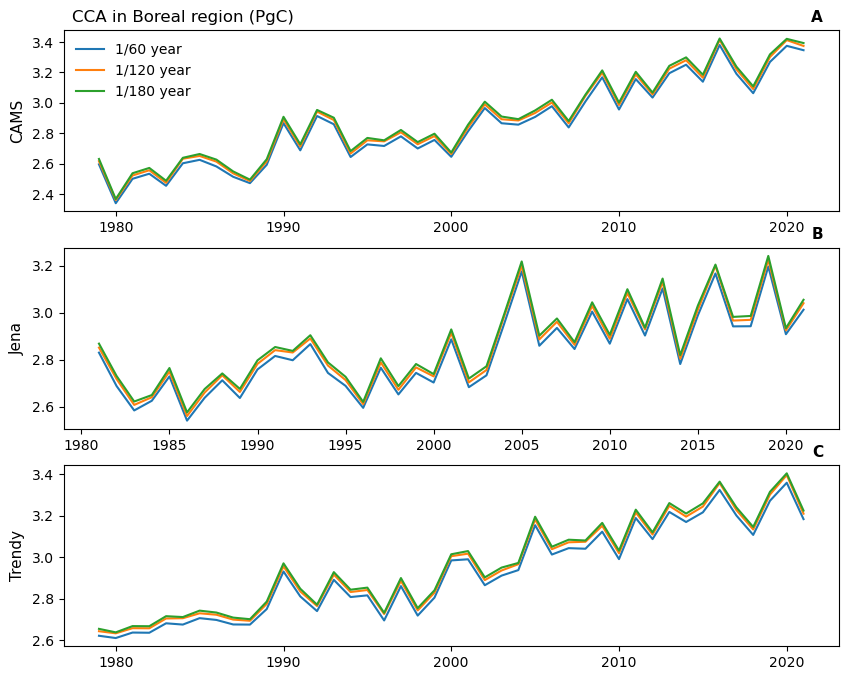

In [6]:
n_cols = 1
n_rows = 3
k = 0.00017
gs = gridspec.GridSpec(n_rows, n_cols, height_ratios=[1]*n_rows, width_ratios=[1]*n_cols, wspace=0.1, hspace=0.2)
fig = plt.figure(figsize=(10, 8))  # 调整画布长宽比以适应竖长布局
axs = np.empty((n_rows, n_cols), dtype=object) # 变为 1D 数组

for i in range(n_rows):
    for j in range(n_cols):
        axs[i, j] = fig.add_subplot(gs[i, j])


for num_p, period in enumerate([60, 120, 180]):
    for num_model, (model, info) in enumerate(model_dict.items()):
        ax = axs[num_model, 0]
        amp = info['amp'][num_p, :]
        amp_exp = info['amp_exp']
        diff = amp - info['amp'].mean(axis=0)
        amp = amp_exp + diff
        time_amp = info['time']

        if model != 'CAMS':
            # 计算二次项修正
            t0 = time_amp.mean()
            t_rel = time_amp - t0
            quad_term = k * t_rel**2 - k * (t_rel.max() + t_rel.min()) * t_rel + k * t_rel.max() * t_rel.min()
            amp = amp + quad_term

        ax.plot(time_amp, amp)

model_list = list(model_dict.keys())
letters = ['A', 'B', 'C']
for i in range(3):
    ax = axs[i, 0]
    ax.text(-0.05, 0.5, model_list[i], transform=ax.transAxes, 
            rotation=90, va='center', ha='right', fontsize=11)
    ax.text(0.98, 1.03, letters[i], transform=ax.transAxes, 
            va='bottom', ha='right', fontsize=11, fontweight='bold')

axs[0, 0].text(0.01, 1.03, 'CCA in Boreal region (PgC)',
               transform=axs[0, 0].transAxes, fontsize=12, va='bottom', ha='left')
axs[0, 0].legend(['1/60 year', '1/120 year', '1/180 year'], loc='upper left', 
                 fontsize=10, frameon=False)

plt.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-method-periods.png',
            dpi=500)